# Seccion 0

In [22]:
#Librerias
import os, sys, random, platform, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore", category=FutureWarning)


In [23]:

#Semilla
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)
rng = np.random.default_rng(SEED)

In [24]:
# ---------- Rutas ----------
DATA_DIR    = Path("../Data/train")   # carpeta con train.csv, meal_info.csv, fulfilment_center_info.csv
RESULTS_DIR = Path("results")
FIG_DIR     = RESULTS_DIR / "figures"
TAB_DIR     = RESULTS_DIR / "tables"
for d in (FIG_DIR, TAB_DIR):          # ya no se crea DATA_DIR
    d.mkdir(parents=True, exist_ok=True)

In [25]:
#Estilo de figuras
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight"})

def savefig(name: str):
    # Guarda la figura actual en results/figures/<name>.png y la muestra.
    plt.savefig(FIG_DIR / f"{name}.png")
    plt.show()

def save_table(df: pd.DataFrame, name: str, index: bool = True):
    # Guarda una tabla en results/tables/<name>.csv.
    df.to_csv(TAB_DIR / f"{name}.csv", index=index)


In [26]:

#Registro del entorno
print("Python      :", sys.version.split()[0], "|", platform.platform())
for lib in (np, pd, sns):
    print(f"{lib.__name__:<11}:", lib.__version__)
print("SEED        :", SEED)

Python      : 3.10.19 | Windows-10-10.0.26200-SP0
numpy      : 2.2.6
pandas     : 2.3.3
seaborn    : 0.13.2
SEED        : 42


# Seccion 1 - Carga de datos

Se usan unicamente los archivos de la carpeta train

In [27]:
#Importacion de datos
train   = pd.read_csv(DATA_DIR / "train.csv")
meals   = pd.read_csv(DATA_DIR / "meal_info.csv")
centers = pd.read_csv(DATA_DIR / "fulfilment_center_info.csv")

print("train  :", train.shape)
print("meals  :", meals.shape)
print("centers:", centers.shape)



train  : (456548, 9)
meals  : (51, 3)
centers: (77, 5)


In [28]:
# Union de df
df = (train
      .merge(meals,   on="meal_id",   how="left", validate="m:1")
      .merge(centers, on="center_id", how="left", validate="m:1"))
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 456548 entries, 0 to 456547
Data columns (total 15 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   id                     456548 non-null  int64  
 1   week                   456548 non-null  int64  
 2   center_id              456548 non-null  int64  
 3   meal_id                456548 non-null  int64  
 4   checkout_price         456548 non-null  float64
 5   base_price             456548 non-null  float64
 6   emailer_for_promotion  456548 non-null  int64  
 7   homepage_featured      456548 non-null  int64  
 8   num_orders             456548 non-null  int64  
 9   category               456548 non-null  object 
 10  cuisine                456548 non-null  object 
 11  city_code              456548 non-null  int64  
 12  region_code            456548 non-null  int64  
 13  center_type            456548 non-null  object 
 14  op_area                456548 non-nu

# Seccion 2: Calidad de datos y EDA

## Estructura, tipos, nulos y duplicados

In [29]:
print("Tipos de dato:")
print(df.dtypes.to_string())

print("\nNulos por columna:")
nulls = df.isna().sum()
print(nulls[nulls > 0].to_string() if nulls.any() else "Sin nulos")

print("\nFilas duplicadas completas        :", df.duplicated().sum())
print("Duplicados en (week, center, meal):", df.duplicated(["week", "center_id", "meal_id"]).sum())
print("Valores únicos de id              :", df["id"].nunique(), "de", len(df))

display(df[["checkout_price", "base_price", "num_orders"]].describe().T)

Tipos de dato:
id                         int64
week                       int64
center_id                  int64
meal_id                    int64
checkout_price           float64
base_price               float64
emailer_for_promotion      int64
homepage_featured          int64
num_orders                 int64
category                  object
cuisine                   object
city_code                  int64
region_code                int64
center_type               object
op_area                  float64

Nulos por columna:
Sin nulos

Filas duplicadas completas        : 0
Duplicados en (week, center, meal): 0
Valores únicos de id              : 456548 de 456548


,count,mean,std,min,25%,50%,75%,max
checkout_price,456548.0,332.238933,152.939723,2.97,228.95,296.82,445.23,866.27
base_price,456548.0,354.156627,160.715914,55.35,243.50,310.46,458.87,866.27
num_orders,456548.0,261.872760,395.922798,13.00,54.00,136.00,324.00,24299.00


No tenemos datos nulos, ni registros duplicados, en todos los casos, el id es unico

## Estructura del panel

Centros: 77 | Comidas: 51 | Series (centro, comida) observadas: 3597
Combinaciones posibles: 3927 -> cobertura del producto cartesiano: 91.6%
Semanas: 1 a 145 (145 únicas) | ¿semanas contiguas?: True

Series completas (145 semanas): 34.7%
Series con huecos internos        : 59.2%


,count,mean,std,min,25%,50%,75%,max
n_obs,3597.0,126.924659,28.807194,1.0,122.0,140.0,145.0,145.0
gaps,3597.0,11.272727,19.988341,0.0,0.0,2.0,13.0,139.0


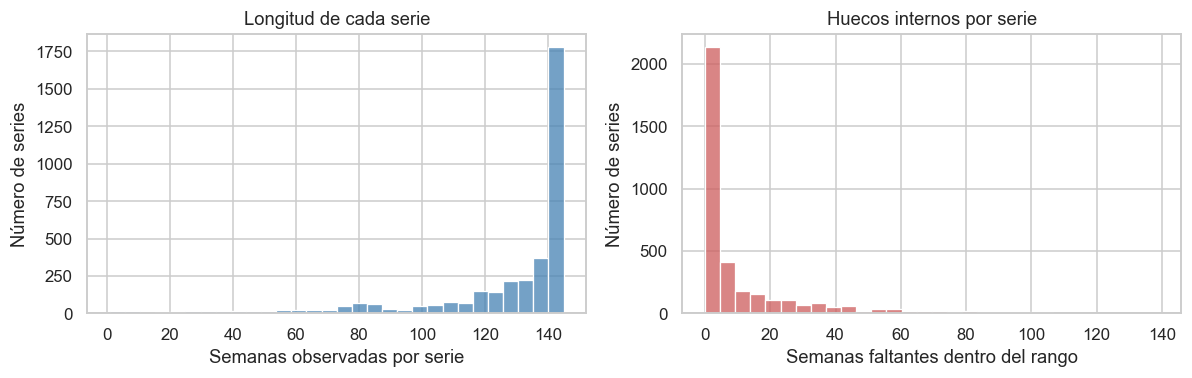

In [30]:
n_centers = df["center_id"].nunique()
n_meals   = df["meal_id"].nunique()
n_series  = df[["center_id", "meal_id"]].drop_duplicates().shape[0]
weeks     = np.sort(df["week"].unique())
n_weeks   = len(weeks)

print(f"Centros: {n_centers} | Comidas: {n_meals} | Series (centro, comida) observadas: {n_series}")
print(f"Combinaciones posibles: {n_centers * n_meals} -> cobertura del producto cartesiano: {n_series/(n_centers*n_meals):.1%}")
print(f"Semanas: {weeks.min()} a {weeks.max()} ({n_weeks} únicas) | ¿semanas contiguas?: {bool((np.diff(weeks) == 1).all())}")

# Longitud de cada serie y huecos internos
g = df.groupby(["center_id", "meal_id"])["week"]
series_stats = pd.DataFrame({
    "n_obs":      g.size(),
    "first_week": g.min(),
    "last_week":  g.max(),
})
series_stats["span"]      = series_stats["last_week"] - series_stats["first_week"] + 1
series_stats["gaps"]      = series_stats["span"] - series_stats["n_obs"]   # semanas faltantes dentro del rango
series_stats["complete"]  = series_stats["n_obs"] == n_weeks

print(f"\nSeries completas ({n_weeks} semanas): {series_stats['complete'].mean():.1%}")
print(f"Series con huecos internos        : {(series_stats['gaps'] > 0).mean():.1%}")
display(series_stats[["n_obs", "gaps"]].describe().T)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
sns.histplot(series_stats["n_obs"], bins=30, ax=ax[0], color="steelblue")
ax[0].set(title="Longitud de cada serie", xlabel="Semanas observadas por serie", ylabel="Número de series")
sns.histplot(series_stats["gaps"], bins=30, ax=ax[1], color="indianred")
ax[1].set(title="Huecos internos por serie", xlabel="Semanas faltantes dentro del rango", ylabel="Número de series")
plt.tight_layout()
savefig("02_panel_longitud_huecos")

### Observaciones
Contamos con 3.597 series centro-comida
La mediana identificada es de 140 semanas de 145, osea que mas o menos la mitad de las series estan completas, con un pico en 145. 
Visualmente se identifican colas largas, la primera es e la distribucion de la longitud que tiene la cola hacia la izquierda, con pocas series siendo bastante cortas, esto no alcanza a describir un perfil de demanda. La segunda grafica indica la cantidad de huecos por serie, donde la mayoria se concentra en 0, y muy pocas se distribuyen en una cola hacia la derecha.

Para hacer PCA, K-means y GMM necesitan de una matriz sin celdas vacias, asi que si hubieran muchos huecos, nos veriamos en la necesidad de inventar data, distorsionando los perfiles. Al observar estos graficos vemos que la mayoria estan completos y que deberiamos elegir un umbral para excluir ese grupo en vez de rellenar


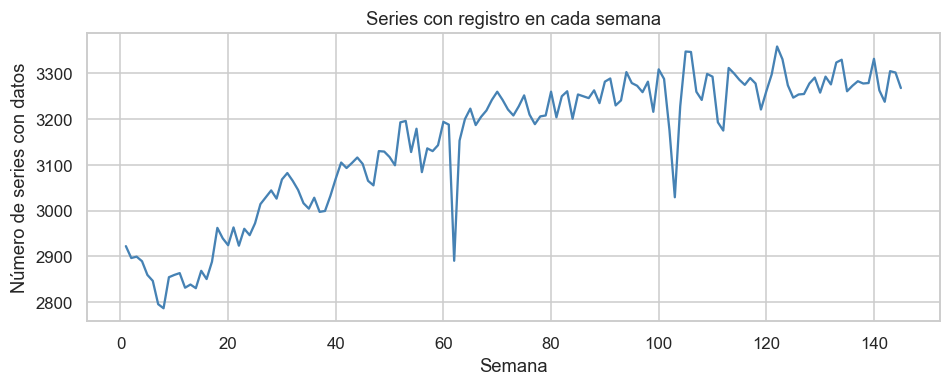

Rango de series activas por semana: 2786 - 3359


In [31]:
#Series observadas por semana.
obs_per_week = df.groupby("week").size()
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(obs_per_week.index, obs_per_week.values, color="steelblue")
ax.set(title="Series con registro en cada semana", xlabel="Semana", ylabel="Número de series con datos")
savefig("02_series_por_semana")
print("Rango de series activas por semana:", obs_per_week.min(), "-", obs_per_week.max())

### Observaciones
Cada semana hay entre 2.786 y 3.359 series con datos, indicando que el panel no es constante en el tiempo.

## Distribucion de ordenes

Mínimo: 13 | Mediana: 136 | Media: 261.9 | P99: 1796 | Máximo: 24299
Asimetría (skew) cruda: 6.93 | tras log1p: -0.02
Pedidos == 0: 0 | Pedidos < 0: 0


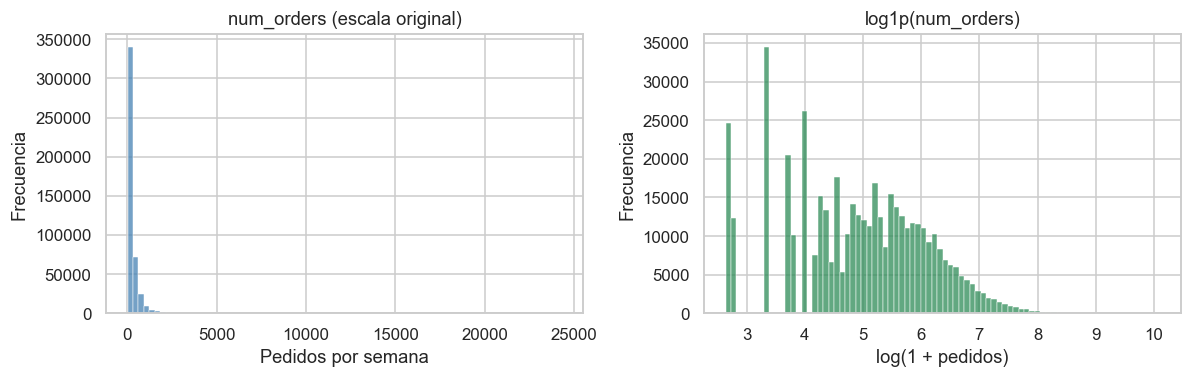

In [32]:
y = df["num_orders"]
print(f"Mínimo: {y.min()} | Mediana: {y.median():.0f} | Media: {y.mean():.1f} | P99: {y.quantile(.99):.0f} | Máximo: {y.max()}")
print(f"Asimetría (skew) cruda: {stats.skew(y):.2f} | tras log1p: {stats.skew(np.log1p(y)):.2f}")
print(f"Pedidos == 0: {(y == 0).sum()} | Pedidos < 0: {(y < 0).sum()}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
sns.histplot(y, bins=80, ax=ax[0], color="steelblue")
ax[0].set(title="num_orders (escala original)", xlabel="Pedidos por semana", ylabel="Frecuencia")
sns.histplot(np.log1p(y), bins=80, ax=ax[1], color="seagreen")
ax[1].set(title="log1p(num_orders)", xlabel="log(1 + pedidos)", ylabel="Frecuencia")
plt.tight_layout()
savefig("02_dist_num_orders")

### Observaciones
La demanda es muy asimétrica (skew 6,93). Con `log1p` baja a casi 0 (-0,02), así que la distribución queda casi simétrica.
No hay pedidos en 0 ni negativos: **una semana sin registro es dato faltante, no "demanda cero"**.
El 10 % de las series con más volumen concentra el **36,9 %** de la demanda: el volumen varía mucho entre series, por eso separamos nivel y forma.

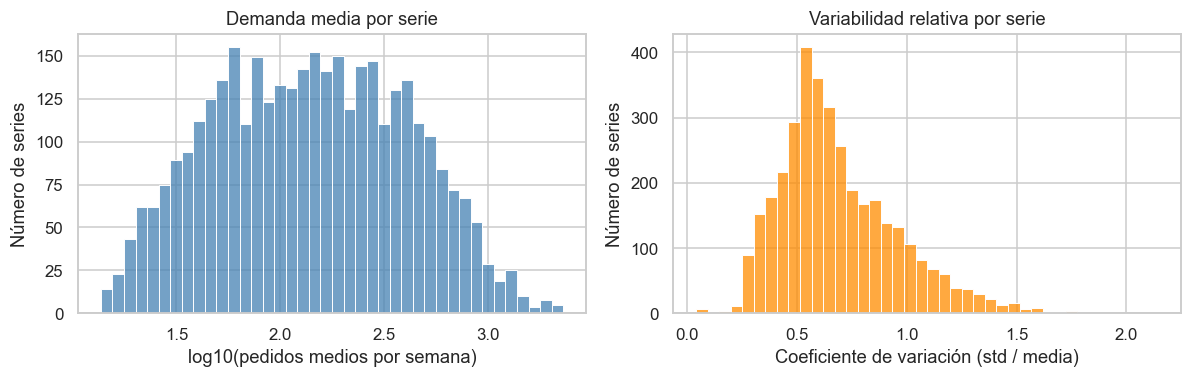

El 10 % de las series con más volumen concentra 36.9% de la demanda media total


In [33]:
# Nivel de demanda por serie: ¿qué tanto varía el volumen entre series?
level = df.groupby(["center_id", "meal_id"])["num_orders"].agg(["mean", "std", "max"])
level["cv"] = level["std"] / level["mean"]          # coeficiente de variación = qué tan 'errática' es la serie

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
sns.histplot(np.log10(level["mean"]), bins=40, ax=ax[0], color="steelblue")
ax[0].set(title="Demanda media por serie", xlabel="log10(pedidos medios por semana)", ylabel="Número de series")
sns.histplot(level["cv"].dropna(), bins=40, ax=ax[1], color="darkorange")
ax[1].set(title="Variabilidad relativa por serie", xlabel="Coeficiente de variación (std / media)", ylabel="Número de series")
plt.tight_layout()
savefig("02_nivel_variabilidad_series")

top10 = level["mean"].sort_values(ascending=False).head(int(0.1 * len(level))).sum() / level["mean"].sum()
print(f"El 10 % de las series con más volumen concentra {top10:.1%} de la demanda media total")

## Precios y promociones

Checkout > base (precio con 'recargo'): 116101 (25.43%)
Precios <= 0: 0
Banderas de promoción (proporción de semanas activas):
emailer_for_promotion    0.081
homepage_featured        0.109
Valores únicos en banderas: [np.int64(0), np.int64(1)] [np.int64(0), np.int64(1)]


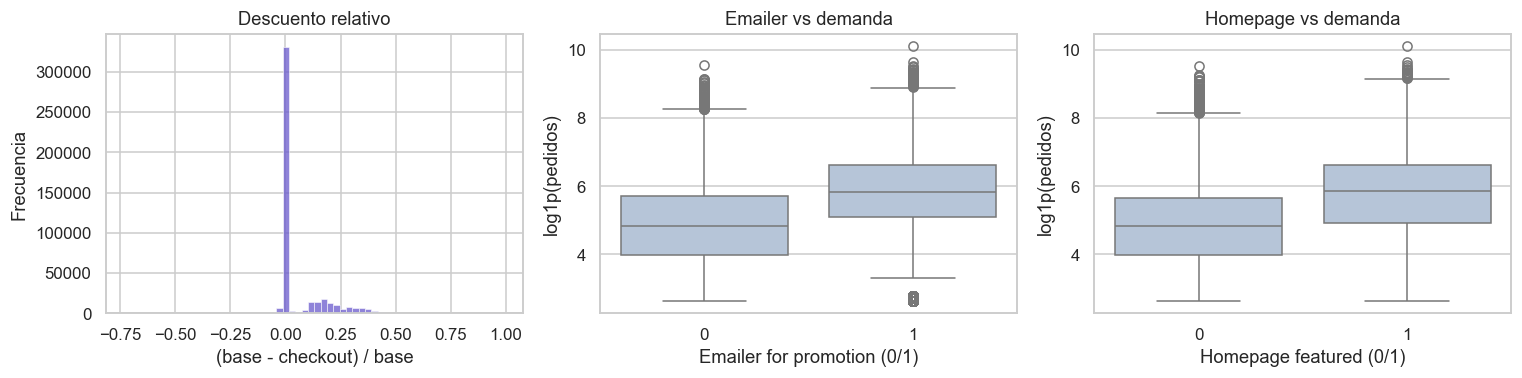

,num_orders,checkout_price,base_price,discount_pct,emailer_for_promotion,homepage_featured
num_orders,1.00,-0.39,-0.34,0.12,0.21,0.23
checkout_price,-0.39,1.00,0.96,-0.14,0.02,-0.06
base_price,-0.34,0.96,1.00,0.07,0.15,0.04
discount_pct,0.12,-0.14,0.07,1.00,0.38,0.27
emailer_for_promotion,0.21,0.02,0.15,0.38,1.00,0.39
homepage_featured,0.23,-0.06,0.04,0.27,0.39,1.00


In [34]:
df["discount"]     = df["base_price"] - df["checkout_price"]
df["discount_pct"] = df["discount"] / df["base_price"]

print("Checkout > base (precio con 'recargo'):", (df["discount"] < 0).sum(), f"({(df['discount'] < 0).mean():.2%})")
print("Precios <= 0:", (df[["checkout_price", "base_price"]] <= 0).any(axis=1).sum())
print("Banderas de promoción (proporción de semanas activas):")
print(df[["emailer_for_promotion", "homepage_featured"]].mean().round(3).to_string())
print("Valores únicos en banderas:", sorted(df["emailer_for_promotion"].unique()), sorted(df["homepage_featured"].unique()))

fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
sns.histplot(df["discount_pct"], bins=60, ax=ax[0], color="slateblue")
ax[0].set(title="Descuento relativo", xlabel="(base - checkout) / base", ylabel="Frecuencia")
sns.boxplot(data=df, x="emailer_for_promotion", y=np.log1p(df["num_orders"]), ax=ax[1], color="lightsteelblue")
ax[1].set(title="Emailer vs demanda", xlabel="Emailer for promotion (0/1)", ylabel="log1p(pedidos)")
sns.boxplot(data=df, x="homepage_featured", y=np.log1p(df["num_orders"]), ax=ax[2], color="lightsteelblue")
ax[2].set(title="Homepage vs demanda", xlabel="Homepage featured (0/1)", ylabel="log1p(pedidos)")
plt.tight_layout()
savefig("02_precios_promociones")

# Asociación descriptiva (NO causal)
corr = df[["num_orders", "checkout_price", "base_price", "discount_pct",
           "emailer_for_promotion", "homepage_featured"]].assign(num_orders=np.log1p(df["num_orders"])).corr(method="spearman")
display(corr.round(2))

Observaciones
Las promociones son poco frecuentes: emailer 8,1 % y homepage 10,9 % de las semanas.
La mayoría de las filas no tiene descuento (pico en 0); cuando hay, ronda entre 10 % y 40 %.
El 25,4 % de las filas tiene `checkout_price` mayor que `base_price`. En la gráfica esos casos se ven cerca de 0, pero conviene confirmar su tamaño.
Las semanas con emailer o homepage tienen mayor demanda (mediana en log1p ≈ 5,8 vs ≈ 4,8). Correlación de Spearman: 0,21 y 0,23.
El precio se relaciona de forma negativa con la demanda (-0,39).
Es una asociación, no causalidad: las promociones no se asignan al azar.

## Dinamica temporal agregada

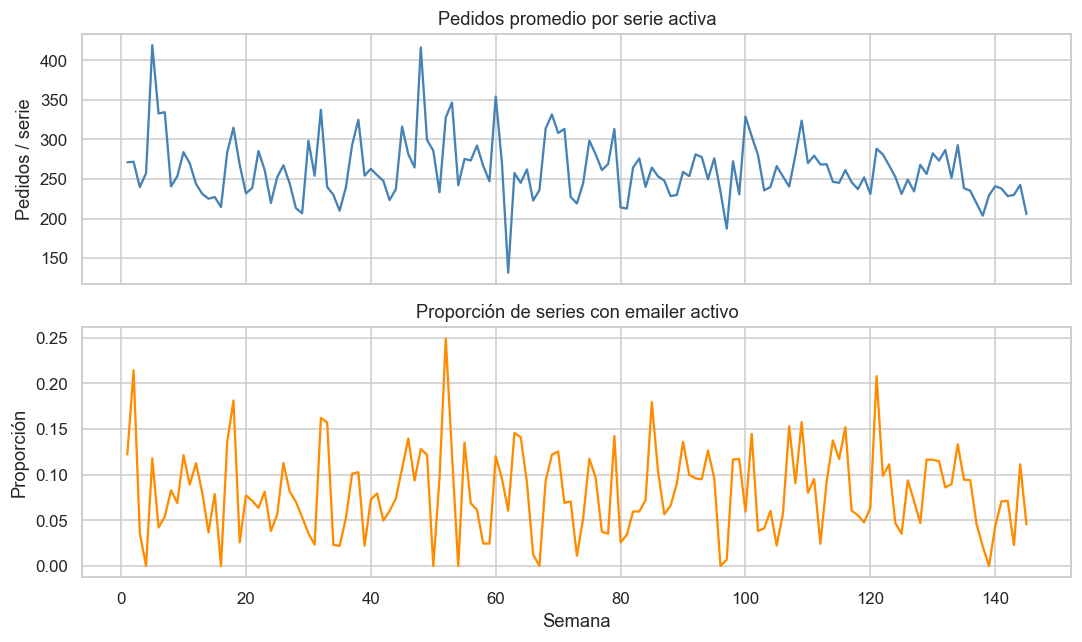

In [35]:
weekly = df.groupby("week").agg(total_orders=("num_orders", "sum"),
                                promo_share=("emailer_for_promotion", "mean"),
                                n_series=("id", "size"))
weekly["orders_per_series"] = weekly["total_orders"] / weekly["n_series"]

fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ax[0].plot(weekly.index, weekly["orders_per_series"], color="steelblue")
ax[0].set(title="Pedidos promedio por serie activa", ylabel="Pedidos / serie")
ax[1].plot(weekly.index, weekly["promo_share"], color="darkorange")
ax[1].set(title="Proporción de series con emailer activo", xlabel="Semana", ylabel="Proporción")
plt.tight_layout()
savefig("02_dinamica_temporal")

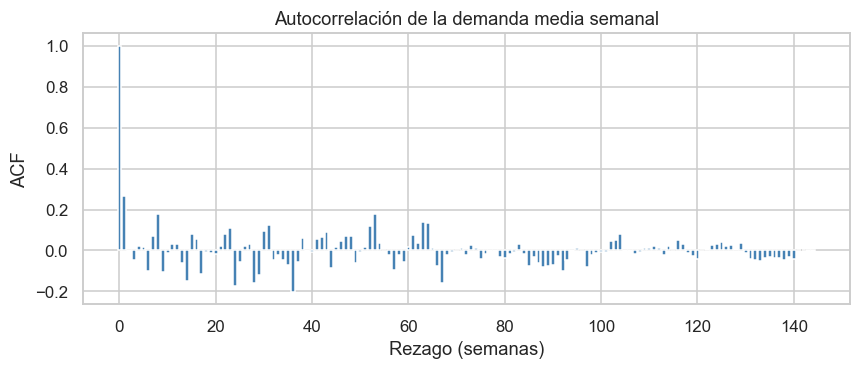

In [36]:
# Estacionalidad: autocorrelación de la demanda media semanal (¿hay ciclo de ~52 semanas o de otro periodo?)
s = weekly["orders_per_series"].values
s = s - s.mean()
acf = np.correlate(s, s, mode="full")[len(s) - 1:] / np.dot(s, s)
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.bar(range(len(acf)), acf, color="steelblue")
ax.set(title="Autocorrelación de la demanda media semanal", xlabel="Rezago (semanas)", ylabel="ACF")
savefig("02_acf_demanda")

**Observaciones**
La demanda media por serie se mantiene estable (≈ 200–350 pedidos), con picos puntuales (~semanas 5 y 48) y una caída marcada cerca de la semana 62.
La proporción de series con emailer oscila entre 0 y 0,25 sin tendencia clara.

## Distribucion de demanda por categoria, cocina y tipo de centro

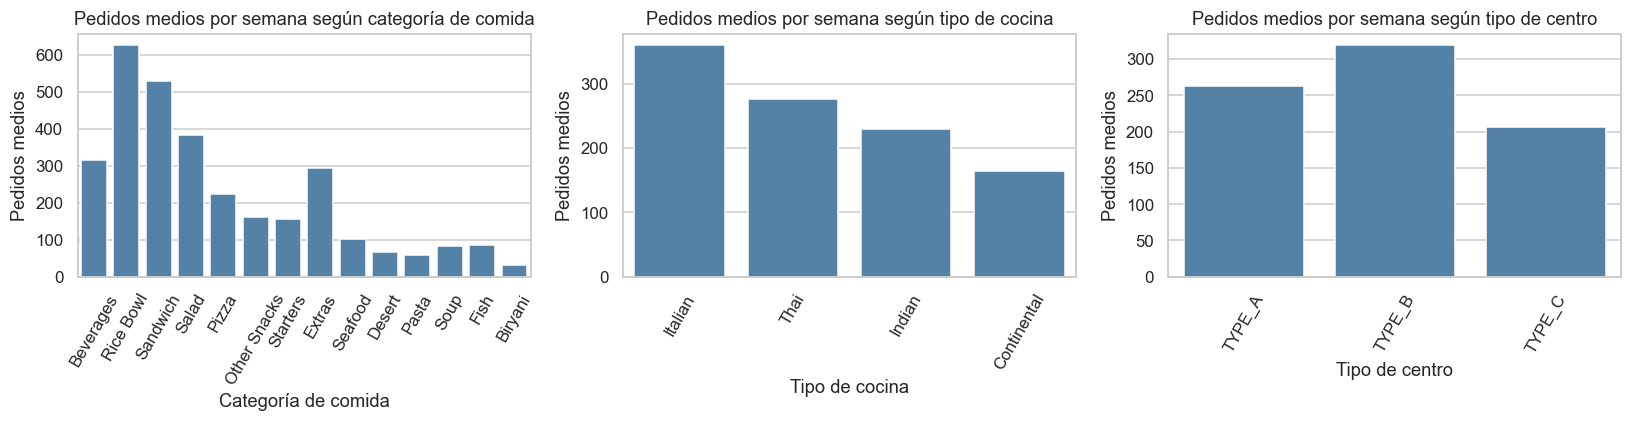

Comidas por categoría:
category
Beverages       12
Extras           3
Soup             3
Other Snacks     3
Salad            3
Rice Bowl        3
Starters         3
Sandwich         3
Pasta            3
Desert           3
Biryani          3
Pizza            3
Fish             3
Seafood          3

Centros por tipo:
center_type
TYPE_A    43
TYPE_C    19
TYPE_B    15


In [37]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, col, title in zip(ax, ["category", "cuisine", "center_type"],
                         ["Categoría de comida", "Tipo de cocina", "Tipo de centro"]):
    order = df.groupby(col)["num_orders"].sum().sort_values(ascending=False).index
    sns.barplot(data=df, x=col, y="num_orders", order=order, estimator=np.mean, errorbar=None, ax=a, color="steelblue")
    a.set(title=f"Pedidos medios por semana según {title.lower()}", xlabel=title, ylabel="Pedidos medios")
    a.tick_params(axis="x", rotation=60)
plt.tight_layout()
savefig("02_metadatos")

print("Comidas por categoría:"); print(meals["category"].value_counts().to_string())
print("\nCentros por tipo:");    print(centers["center_type"].value_counts().to_string())

**Observaciones**
La demanda difiere mucho entre categorías: Rice Bowl y Sandwich lideran (> 500 pedidos/semana) y Biryani queda abajo (~30).
Por cocina: Italian > Thai > Indian > Continental.
Por centro: TYPE_B tiene la mayor demanda media (~320), TYPE_C la menor (~205).
Hay 51 comidas en 14 categorías: Beverages tiene 12 y las demás 3 cada una. Esto servirá para interpretar los clústeres.

# Seccion 3: Tabla de decisiones de preprocesamiento

## Series por semanas, sensibilidad de umbrales

### Justificacion
Usamos una racha en vez de el total ya que interpolar 2 semanas seguidas es mejor que interpolar 20, lo que seria inventar una porcion del perfil. La racha tambien toma en cuenta los huecos del inicio y final de la serie 

In [ ]:
# Matriz (centro, comida) x semana. NaN = no hay registro esa semana
M_raw = df.pivot(index=["center_id", "meal_id"], columns="week", values="num_orders")
M_raw = M_raw.reindex(columns=range(int(df["week"].min()), int(df["week"].max()) + 1))
N_WEEKS = M_raw.shape[1]
print("Matriz series x semanas:", M_raw.shape, "| celdas vacías:", f"{M_raw.isna().mean().mean():.1%}")

def max_run(mask: np.ndarray) -> np.ndarray:
    # Longitud de la racha mas largas de semanas faltantes consecutivas en cada fila (mask = True si falta).
    best = np.zeros(mask.shape[0], dtype=int)
    cur  = np.zeros(mask.shape[0], dtype=int)
    for j in range(mask.shape[1]):
        cur  = (cur + 1) * mask[:, j]
        best = np.maximum(best, cur)
    return best

n_obs   = M_raw.notna().sum(axis=1)
run_gap = pd.Series(max_run(M_raw.isna().to_numpy()), index=M_raw.index, name="max_run")

display(pd.DataFrame({"n_obs": n_obs, "racha_max_faltante": run_gap}).describe().T.round(1))

Matriz series x semanas: (3597, 145) | celdas vacías: 12.5%


,count,mean,std,min,25%,50%,75%,max
n_obs,3597.0,126.9,28.8,1.0,122.0,140.0,145.0,145.0
racha_max_faltante,3597.0,9.1,20.5,0.0,0.0,1.0,5.0,142.0


Observaciones

La mediana de `n_obs` es 140 de 145 semanas y la mediana de la racha de faltantes es 1 semana: la mayoría de las series casi no tiene huecos seguidos.
El 25 % de las series tiene rachas de 5 semanas o más y el máximo llega a 142, es decir, hay series casi sin datos.
En la matriz completa el 12,5 % de las celdas está vacío.

In [39]:
# Sensibilidad: ¿cuántas series se conservan y cuántas celdas habría que imputar?
rows = []
for min_cov in (0.7, 0.8, 0.9):
    for max_r in (4, 8, 12, 16):
        k = (n_obs >= min_cov * N_WEEKS) & (run_gap <= max_r)
        imputed = M_raw[k].isna().sum().sum() / (k.sum() * N_WEEKS)
        rows.append({"min_cobertura": min_cov, "max_racha_sem": max_r,
                     "series_conservadas": int(k.sum()), "porcentaje": round(k.mean(), 3),
                     "celdas_a_imputar": round(imputed, 4)})
sens = pd.DataFrame(rows)
save_table(sens, "sensibilidad_umbral_series", index=False)
display(sens)

,min_cobertura,max_racha_sem,series_conservadas,porcentaje,celdas_a_imputar
0,0.7,4,2594,0.721,0.0356
1,0.7,8,2723,0.757,0.0412
2,0.7,12,2775,0.771,0.0424
3,0.7,16,2852,0.793,0.0445
4,0.8,4,2500,0.695,0.0277
5,0.8,8,2586,0.719,0.0302
6,0.8,12,2631,0.731,0.0311
7,0.8,16,2703,0.751,0.0332
8,0.9,4,2274,0.632,0.0160
9,0.9,8,2320,0.645,0.0170


Observaciones


 Con cobertura de 80 %, pasar de racha máxima 4 a 8 semanas recupera solo 86 series (2.500 → 2.586). Subir a 16 recupera 117 más.

 Exigir 90 % de cobertura cuesta unas 270 series más (2.586 → 2.320 con racha 8).

 Con 80 % y racha 8 se conservan 2.586 series y se imputa solo el 3,0 % de las celdas.
Decidimos que `MIN_COV = 0.8` y `MAX_RUN = 8`. Es un punto intermedio: pocas celdas inventadas sin perder demasiadas series.

## Eleccion de parametros

In [ ]:
# PARÁMETROS DE PREPROCESAMIENTO 
MIN_COV   = 0.80    # fracción mínima de semanas observadas por serie
MAX_RUN   = 8       # racha máxima de semanas faltantes consecutivas que se tolera
MA_WINDOW = 4       # ventana de media móvil  para suavizar ruido de conteo
SPLIT_WEEK = 72     # corte para la prueba de estabilidad: semanas 1-72 vs 73-145

keep = (n_obs >= MIN_COV * N_WEEKS) & (run_gap <= MAX_RUN)
print(f"Series conservadas: {keep.sum()} de {len(keep)} ({keep.mean():.1%})")
print(f"Celdas a imputar en las series conservadas: {M_raw[keep].isna().mean().mean():.2%}")

Series conservadas: 2586 de 3597 (71.9%)
Celdas a imputar en las series conservadas: 3.02%


In [41]:
# Bias en el filtro 
# Comparar conservadas vs descartadas.
meta = (pd.DataFrame(index=M_raw.index).reset_index()
          .merge(meals, on="meal_id", how="left").merge(centers, on="center_id", how="left")
          .set_index(["center_id", "meal_id"]))
meta["conservada"] = keep.loc[meta.index].values
meta["log_volumen"] = np.log1p(M_raw).mean(axis=1).loc[meta.index].values

print("Volumen medio (log1p) por grupo:")
display(meta.groupby("conservada")["log_volumen"].agg(["count", "mean"]).round(2))

for col in ["center_type", "category"]:
    t = (meta.groupby(col)["conservada"].agg(["size", "mean"])
             .rename(columns={"size": "series", "mean": "prop_conservada"})
             .sort_values("prop_conservada").round(3))
    save_table(t, f"sesgo_filtro_{col}")
    display(t)

Volumen medio (log1p) por grupo:


,count,mean
conservada,,
False,1011,4.18
True,2586,4.98


,series,prop_conservada
center_type,,
TYPE_C,864,0.611
TYPE_A,2020,0.751
TYPE_B,713,0.757


,series,prop_conservada
category,,
Fish,163,0.000
Salad,231,0.000
Biryani,228,0.237
Other Snacks,231,0.628
Seafood,228,0.632
Pasta,230,0.691
Soup,103,0.757
Extras,108,0.769
Desert,230,0.839


Observaciones
- Se conserva el 71,9 % de las series (2.586 de 3.597).
- Las series descartadas tienen menos volumen (log1p medio 4,18 frente a 4,98): el filtro favorece comidas de mayor demanda.
- Por tipo de centro, TYPE_C conserva menos (61 %) que TYPE_A y TYPE_B (75 %).
- **Por categoría el sesgo es fuerte:** Fish y Salad quedan en 0 % y Biryani en 24 %, mientras Pizza, Rice Bowl y Sandwich superan el 98 %.
- Esto es un **sesgo de supervivencia**, con tres causas distintas:
  1. **Fish** se lanzó hacia la semana 63 (mediana ~77 semanas observadas): historia insuficiente.
  - **Salad** empieza hacia la semana 20: tiene cobertura suficiente, pero la regla de racha la excluye por las ~19 semanas previas a su lanzamiento.
  - **Biryani** se ofrece de forma intermitente (~92 semanas observadas).
- Los resultados describen comidas con historial largo y estable; no representan a Fish, Salad ni en buena parte Biryani. Esto lo tomamos como limitación.

## Tabla de decisiones

| # | Decisión | Justificación | Impacto |
|---|----------|---------------|---------|
| 1 | Descartar `test.csv` y `sample_submission` | No tienen `num_orders`; el problema es no supervisado sobre la demanda observada. | Evita confundir conjuntos y cualquier fuga. |
| 2 | Unidad de análisis: serie (`center_id`, `meal_id`) con las semanas como variables | Responde la pregunta de perfiles de demanda por combinación centro-comida. | Matriz de series × 145 semanas. |
| 3 | Filtro de series: ≥ 80 % de semanas observadas y racha de faltantes ≤ 8 semanas | Las series cortas no describen un perfil; las rachas largas obligarían a inventar tramos del perfil (sensibilidad en 3.1). | Se conservan 2.586 de 3.597 series (71,9 %). |
| 4 | Se aceptan las exclusiones de Fish, Salad y (en parte) Biryani | Fish se lanzó hacia la semana 63 y Biryani se ofrece de forma intermitente: no hay historia suficiente. Salad empieza hacia la semana 20; rellenar ~19 semanas previas con un valor plano inventaría el perfil. | Sesgo de supervivencia: las conclusiones aplican a comidas con historial largo. |
| 5 | Huecos: interpolación lineal; en el inicio y el final se repite el valor observado más cercano | No hay ceros en los datos (mínimo 13 pedidos), así que un faltante no es "demanda cero"; rellenar con 0 crearía caídas falsas. | Se imputa el 3,02 % de las celdas (11.309). |
| 6 | Transformar `num_orders` con `log1p` | La asimetría es 6,93 en escala original y −0,02 con `log1p` (sección 2.3). | Evita que unos pocos valores extremos dominen PCA, K-means y GMM. |
| 7 | Valores extremos: se conservan | Pueden ser promociones reales y no errores; `log1p` ya atenúa su peso. | No se elimina información; se reporta como limitación. |
| 8 | Suavizado: media móvil centrada de 4 semanas, dentro de cada ventana de análisis | Reduce el ruido de conteo semanal sin borrar la forma del perfil. | Introduce autocorrelación artificial; se declara como limitación. |
| 9 | Dos vistas: FORMA (z-score por serie) y NIVEL (log-volumen medio) | El volumen varía por órdenes de magnitud (el 10 % de las series concentra el 36,9 % de la demanda): se separa "cuánto" de "cómo". | Los clústeres de forma no reflejan solo el tamaño de la serie. |
| 10 | Precio, descuento, promociones y metadatos fuera de las variables del modelo | Se usan solo para interpretar los grupos; meterlos al modelo y luego "descubrirlos" sería circular. | Interpretación como asociación, nunca como causa. |
| 11 | Análisis principal con todo el periodo; estabilidad con dos mitades temporales (semanas 1-72 y 73-145) | La pregunta es descriptiva (perfiles en el periodo observado). La estabilidad se mide agrupando cada mitad por separado y comparando con ARI. | Evita afirmar generalización sin evidencia fuera de muestra. |

# Seccion 4: Preprocesamiento


| Objeto | Qué es |
|---|---|
| `M` | Series conservadas x semanas, en pedidos, con huecos interpolados |
| `Z` | **Vista FORMA**: log1p, media móvil y z-score por serie (todo el periodo) |
| `vol` | **Vista NIVEL**: log-volumen medio por serie |
| `Z_h1`, `Z_h2` | Misma vista de forma, calculada por separado para cada mitad (prueba de estabilidad) |
| `info` | Variables para **interpretar** (descuento, promociones, metadatos); no entran al modelo |

## Filtro de series

In [42]:
M_f  = M_raw[keep]                         # series conservadas (con NaN)
imputed_mask = M_f.isna()                  # qué celdas se imputan (para auditar)

# Interpolación lineal por fila (semanas contiguas y equiespaciadas); en los bordes se repite el valor más cercano
M = M_f.interpolate(axis=1, method="linear", limit_direction="both")

assert not M.isna().any().any(), "Quedaron celdas vacías tras la interpolación"
print("M:", M.shape, "| celdas imputadas:", int(imputed_mask.sum().sum()),
      f"({imputed_mask.mean().mean():.2%})")

M: (2586, 145) | celdas imputadas: 11309 (3.02%)


## Vistas de forma

In [43]:
def shape_view(M: pd.DataFrame, cols, window: int = MA_WINDOW):
    # Devuelve (L, Z) usando SOLO las semanas 'cols':
    # L = log1p suavizado con media móvil centrada; Z = z-score por serie (media 0, desviación 1).
    L = np.log1p(M[cols]).T.rolling(window, center=True, min_periods=1).mean().T
    Z = L.sub(L.mean(axis=1), axis=0).div(L.std(axis=1) + 1e-9, axis=0)
    return L, Z

all_weeks = list(M.columns)
L, Z = shape_view(M, all_weeks)

# Vista NIVEL: cuánto se vende (log-volumen medio); va aparte para que no domine la forma
vol = np.log1p(M).mean(axis=1).rename("log_volumen")

# Verificaciones
n_const = int((L.std(axis=1) < 1e-6).sum())
print("Z:", Z.shape, "| NaN:", int(Z.isna().sum().sum()))
print(f"Media por serie (|max|): {Z.mean(axis=1).abs().max():.1e} | desviación por serie: {Z.std(axis=1).min():.3f} - {Z.std(axis=1).max():.3f}")
print("Series constantes (sin forma):", n_const)
assert not Z.isna().any().any()

Z: (2586, 145) | NaN: 0
Media por serie (|max|): 6.9e-15 | desviación por serie: 1.000 - 1.000
Series constantes (sin forma): 0


## Prueba de estabilidad

In [ ]:
cols_h1 = [w for w in all_weeks if w <= SPLIT_WEEK]
cols_h2 = [w for w in all_weeks if w >  SPLIT_WEEK]

# Se recalcula suavizado y z-score DENTRO de cada mitad, la forma de cada mitad no usa información de la otra.
_, Z_h1 = shape_view(M, cols_h1)
_, Z_h2 = shape_view(M, cols_h2)
print(f"Mitad 1: semanas {cols_h1[0]}-{cols_h1[-1]} -> {Z_h1.shape} | Mitad 2: semanas {cols_h2[0]}-{cols_h2[-1]} -> {Z_h2.shape}")
assert (Z_h1.index == Z_h2.index).all() and (Z.index == Z_h1.index).all()

Mitad 1: semanas 1-72 -> (2586, 72) | Mitad 2: semanas 73-145 -> (2586, 73)


Se calcularon dos matrices independientes: semanas 1-72 (72 semanas) y 73-145 (73 semanas), para las mismas 2.586 series. A su vez el suavizado y el z-score se recalculan dentro de cada mitad, así que ninguna usa información de la otra.

## Variables de interpretacion 

In [45]:
# Promedio por serie de descuento y banderas de promoción; metadatos de comida y centro.
# Descuento = 1 - checkout/base (negativo = checkout mayor que el precio base).
info = (df.assign(descuento=1 - df["checkout_price"] / df["base_price"])
          .groupby(["center_id", "meal_id"])[["descuento", "emailer_for_promotion", "homepage_featured", "checkout_price", "base_price"]]
          .mean()
          .loc[M.index])

meta_k = (pd.DataFrame(index=M.index).reset_index()
            .merge(meals, on="meal_id", how="left").merge(centers, on="center_id", how="left")
            .set_index(["center_id", "meal_id"]))
info = info.join(meta_k).join(vol)

assert len(info) == len(M) and info.index.equals(M.index)
save_table(info, "info_series_interpretacion")
display(info.head())

descuento  emailer_for_promotion  homepage_featured  \
center_id meal_id                                                        
10        1062      0.035584               0.027586           0.055172   
          1109      0.087049               0.096552           0.110345   
          1198      0.102316               0.000000           0.082759   
          1207      0.095501               0.083333           0.159722   
          1216      0.048807               0.048951           0.069930   

                   checkout_price  base_price   category      cuisine  \
center_id meal_id                                                       
10        1062         174.838000  181.382345  Beverages      Italian   
          1109         271.829034  298.660552  Rice Bowl       Indian   
          1198         172.438690  193.352897     Extras         Thai   
          1207         382.214028  426.017639  Beverages  Continental   
          1216         392.665664  413.274196      Pasta      Italian   

                   city_code  region_code center_type  op_area  log_volumen  
center_id meal_id                                                            
10        1062           590           56      TYPE_B      6.3     6.814128  
          1109           590           56      TYPE_B      6.3     7.258002  
          1198           590           56      TYPE_B      6.3     5.765852  
          1207           590           56      TYPE_B      6.3     5.096902  
          1216           590           56      TYPE_B      6.3     4.885699

info reúne para cada serie el descuento medio, la frecuencia de promociones, el precio y los metadatos de comida y centro.
Es importante tener en cuenta que estas variables no entran al modelo: se usan después para interpretar los grupos como asociación, no como causa.

## Antes vs despues

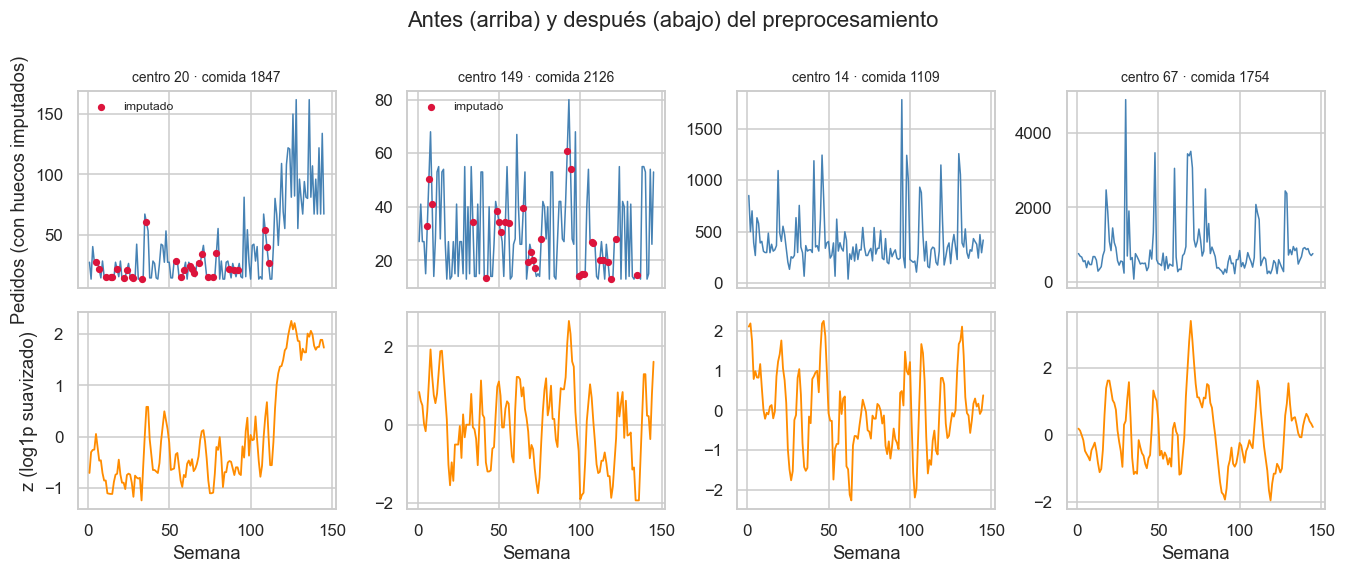

In [ ]:
# 2 series con imputación y 2 series completas elegidas al azar
rng_v = np.random.default_rng(SEED)
con_imp = imputed_mask.sum(axis=1).sort_values(ascending=False)
idx_imp = list(con_imp[con_imp > 0].index[:2])
idx_ok  = list(rng_v.choice(con_imp[con_imp == 0].index.to_numpy(), size=2, replace=False)) if (con_imp == 0).sum() >= 2 else []
ejemplos = [tuple(i) for i in idx_imp + idx_ok][:4]

fig, ax = plt.subplots(2, len(ejemplos), figsize=(3.1 * len(ejemplos), 5.2), sharex=True, squeeze=False)
for j, key in enumerate(ejemplos):
    y_  = M.loc[key]
    msk = imputed_mask.loc[key]
    ax[0, j].plot(y_.index, y_.values, color="steelblue", lw=1)
    ax[0, j].scatter(y_.index[msk.values], y_[msk].values, color="crimson", s=14, zorder=3,
                     label="imputado" if msk.any() else None)
    ax[0, j].set_title(f"centro {key[0]} · comida {key[1]}", fontsize=9)
    if msk.any(): ax[0, j].legend(frameon=False, fontsize=8)
    ax[1, j].plot(Z.columns, Z.loc[key].values, color="darkorange", lw=1.2)
    ax[1, j].set_xlabel("Semana")
ax[0, 0].set_ylabel("Pedidos (con huecos imputados)")
ax[1, 0].set_ylabel("z (log1p suavizado)")
fig.suptitle("Antes (arriba) y después (abajo) del preprocesamiento", y=1.0)
plt.tight_layout()
savefig("04_antes_despues")


- Los puntos rojos (valores imputados) siguen la tendencia de la serie y no generan saltos artificiales.
- La serie del centro 149 comida 2126 tiene muchos huecos dispersos y aun así conserva su forma tras el suavizado.
- La serie del centro 20 comida 1847 muestra un cambio de nivel (sube hacia la semana 110): el z-score lo convierte en una tendencia, que es el tipo de perfil que debe separar el clustering.
- Las series de los centros 14 y 67 muestran picos puntuales; la media móvil los atenúa sin eliminarlos.

# Seccion 5: Linea base

| Paso | Qué se hace | Rúbrica |
|---|---|---|
| 5.1 | PCA: varianza explicada, componentes e interpretación; verificación con SVD | SVD / PCA |
| 5.2 | PCA probabilístico: verosimilitud para elegir el número de componentes | PCA probabilístico |
| 5.3 | K-means: codo, silueta y Davies-Bouldin; regla para elegir `k` | Planteamiento |
| 5.4 | Perfiles de cada grupo y visualización | Interpretación |
| 5.5 | Estabilidad: semillas y mitades temporales (ARI) | Validación |
| 5.6 | Relación de los grupos con precio, promoción y metadatos | Interpretación |

In [47]:
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score
from sklearn.model_selection import cross_val_score

In [ ]:

# ---------- Parámetros de la sección ----------
VAR_TARGET  = 0.80     # varianza acumulada que debe retener el PCA
MAX_PC      = 15       # tope de componentes para no clusterizar en un espacio demasiado grande
K_RANGE     = range(2, 11)
K_MIN_VALID = 3        # k = 2 solo parte en dos y no sirve para políticas de inventario diferenciadas
N_INIT      = 20       # reinicios de K-means para mitigar óptimos locales

Zv    = Z.to_numpy()
weeks = Z.columns.to_numpy()
print("Z:", Zv.shape)

Z: (2586, 145)


## PCA

PCA busca las direcciones (combinaciones de semanas) en las que las series más varían. El primer componente es el patrón semanal que más separa a las series; el segundo, el siguiente patrón **ortogonal** al primero, y así. Se calcula con la **SVD** de la matriz centrada: los valores singulares dan la varianza de cada componente.

Componentes para 80% de varianza: 21 | para 90 %: 32
N_PC elegido = 15 (retiene 71.8% de la varianza)
Varianza explicada, primeros 8 componentes (%): [12.6  8.5  7.4  6.5  5.2  4.9  4.   3.8]
Diferencia máxima PCA vs SVD (varianza explicada): 1.1102230246251565e-16


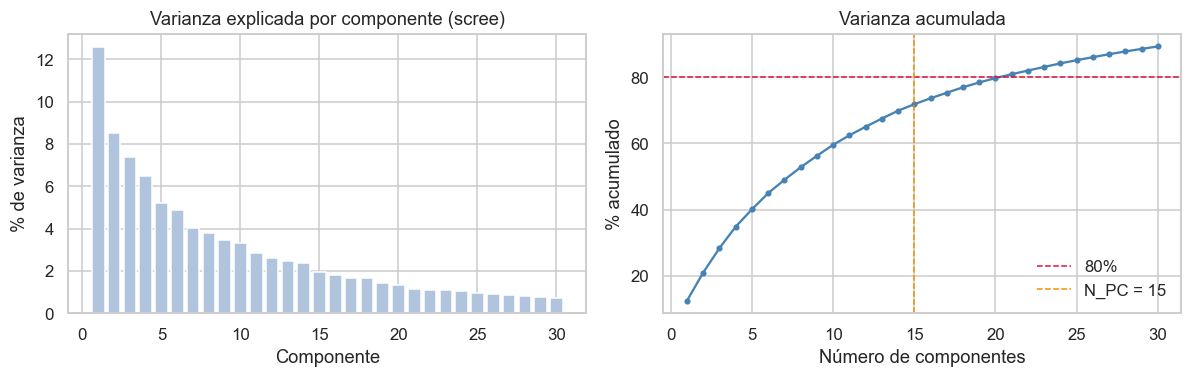

In [49]:
pca_full = PCA(svd_solver="full", random_state=SEED).fit(Zv)
evr = pca_full.explained_variance_ratio_
cum = np.cumsum(evr)

k80 = int(np.searchsorted(cum, VAR_TARGET) + 1)
k90 = int(np.searchsorted(cum, 0.90) + 1)
N_PC = int(min(k80, MAX_PC))
print(f"Componentes para {VAR_TARGET:.0%} de varianza: {k80} | para 90 %: {k90}")
print(f"N_PC elegido = {N_PC} (retiene {cum[N_PC-1]:.1%} de la varianza)")
print("Varianza explicada, primeros 8 componentes (%):", (evr[:8] * 100).round(1))

# Verificación: PCA == SVD de la matriz centrada
Zc = Zv - Zv.mean(axis=0)
_, S, Vt = np.linalg.svd(Zc, full_matrices=False)
evr_svd = S**2 / (S**2).sum()
print("Diferencia máxima PCA vs SVD (varianza explicada):", float(np.abs(evr - evr_svd).max()))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
n_show = 30
ax[0].bar(range(1, n_show + 1), evr[:n_show] * 100, color="lightsteelblue")
ax[0].set(title="Varianza explicada por componente (scree)", xlabel="Componente", ylabel="% de varianza")
ax[1].plot(range(1, n_show + 1), cum[:n_show] * 100, "o-", color="steelblue", ms=3)
ax[1].axhline(VAR_TARGET * 100, color="crimson", ls="--", lw=1, label=f"{VAR_TARGET:.0%}")
ax[1].axvline(N_PC, color="darkorange", ls="--", lw=1, label=f"N_PC = {N_PC}")
ax[1].set(title="Varianza acumulada", xlabel="Número de componentes", ylabel="% acumulado"); ax[1].legend(frameon=False)
plt.tight_layout()
savefig("05_pca_varianza")

- La varianza se reparte entre muchos componentes: PC1 explica 12,6 %, PC2 8,5 % y PC3 7,4 %. Los tres primeros suman solo 28,5 %.
- Hacen falta 21 componentes para el 80 % de la varianza y 32 para el 90 %. Con el tope `N_PC = 15` se retiene el 71,8 %.
- No hay una estructura de pocas dimensiones dominante: los perfiles semanales son ricos y variados.
- La verificación con SVD coincide (diferencia ≈ 1e-16).

## PCA probabilistico

Cada serie se explica con unos pocos factores latentes más ruido. Eso permite calcular una verosimilitud, y con ella elegir el número de componentes de forma objetiva: se ajusta con unas series y se evalúa la log-verosimilitud en series no usadas en el ajuste (validación cruzada sobre series).

Máximo de la log-verosimilitud (validación cruzada, 5 pliegues): k = 40


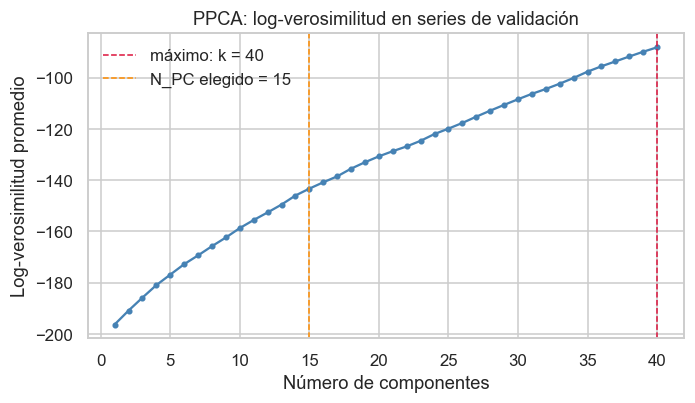

In [50]:
ks = list(range(1, 41))
cv_ll = [cross_val_score(PCA(n_components=k, svd_solver="full", random_state=SEED), Zv, cv=5).mean() for k in ks]
k_ppca = ks[int(np.argmax(cv_ll))]
print(f"Máximo de la log-verosimilitud (validación cruzada, 5 pliegues): k = {k_ppca}")

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(ks, cv_ll, "o-", color="steelblue", ms=3)
ax.axvline(k_ppca, color="crimson", ls="--", lw=1, label=f"máximo: k = {k_ppca}")
ax.axvline(N_PC, color="darkorange", ls="--", lw=1, label=f"N_PC elegido = {N_PC}")
ax.set(title="PPCA: log-verosimilitud en series de validación", xlabel="Número de componentes", ylabel="Log-verosimilitud promedio")
ax.legend(frameon=False)
savefig("05_ppca_cv")


- La log-verosimilitud con validación cruzada alcanza su máximo en k = 40, el borde del rango probado: la curva no se estabiliza antes.
- Los datos sostienen más estructura que los 15 componentes usados. `N_PC = 15` es un compromiso: se clusteriza en pocas dimensiones para que el ruido no domine las distancias.

## K-means en el espacio PCA

Buscamos grupos aproximadamente esféricos y de tamaño parecido; la partición depende de la inicialización (por eso `n_init = 20`).

,k,inercia,silueta,davies_bouldin,calinski_harabasz
0,2,230529.010,0.120,2.656,359.035
1,3,211111.557,0.129,2.288,314.742
2,4,195756.374,0.137,2.215,293.713
3,5,184657.485,0.134,2.248,272.215
4,6,174754.757,0.151,2.078,259.263
5,7,165720.430,0.164,2.008,251.177
6,8,157267.508,0.172,1.955,246.572
7,9,149768.326,0.179,1.831,242.595
8,10,144172.775,0.186,1.761,235.031


k elegido (mayor silueta con k >= 3): 10


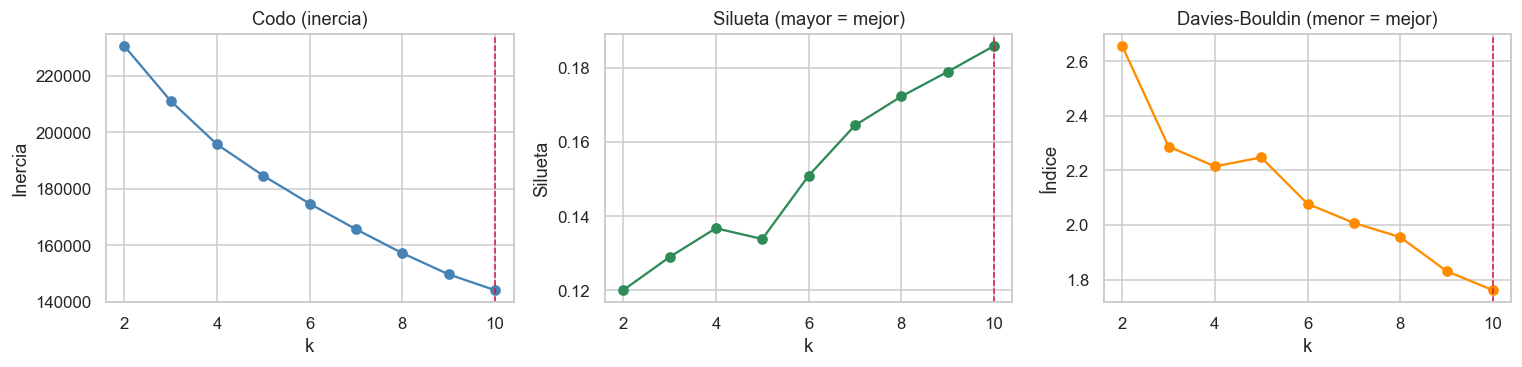

In [51]:
pca = PCA(n_components=N_PC, svd_solver="full", random_state=SEED).fit(Zv)
T = pca.transform(Zv)

rows = []
for k in K_RANGE:
    km = KMeans(k, n_init=N_INIT, random_state=SEED).fit(T)
    rows.append({"k": k, "inercia": km.inertia_,
                 "silueta": silhouette_score(T, km.labels_),
                 "davies_bouldin": davies_bouldin_score(T, km.labels_),
                 "calinski_harabasz": calinski_harabasz_score(T, km.labels_)})
res_km = pd.DataFrame(rows)
K_KM = int(res_km[res_km["k"] >= K_MIN_VALID].sort_values("silueta").iloc[-1]["k"])
save_table(res_km.round(4), "05_kmeans_metricas", index=False)
display(res_km.round(3))
print(f"k elegido (mayor silueta con k >= {K_MIN_VALID}): {K_KM}")

fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
ax[0].plot(res_km["k"], res_km["inercia"], "o-", color="steelblue")
ax[0].set(title="Codo (inercia)", xlabel="k", ylabel="Inercia")
ax[1].plot(res_km["k"], res_km["silueta"], "o-", color="seagreen")
ax[1].set(title="Silueta (mayor = mejor)", xlabel="k", ylabel="Silueta")
ax[2].plot(res_km["k"], res_km["davies_bouldin"], "o-", color="darkorange")
ax[2].set(title="Davies-Bouldin (menor = mejor)", xlabel="k", ylabel="Índice")
for a in ax: a.axvline(K_KM, color="crimson", ls="--", lw=1)
plt.tight_layout()
savefig("05_kmeans_seleccion_k")

In [ ]:
km_final = KMeans(K_KM, n_init=N_INIT, random_state=SEED).fit(T)
lab = pd.Series(km_final.labels_, index=Z.index, name="cluster")
print("Tamaño de cada grupo:"); print(lab.value_counts().sort_index().to_string())

# Comparar con K-means directamente sobre las 145 semanas
lab_raw = KMeans(K_KM, n_init=N_INIT, random_state=SEED).fit_predict(Zv)
print(f"\nARI entre K-means en PCA ({N_PC} comp.) y K-means en Z completa: {adjusted_rand_score(lab, lab_raw):.3f}")

Tamaño de cada grupo:
cluster
0    251
1    371
2    228
3    403
4    315
5    145
6    217
7    357
8    218
9     81

ARI entre K-means en PCA (15 comp.) y K-means en Z completa: 0.751



- La inercia baja de forma suave, sin un codo claro. La silueta sube de 0,12 a 0,186 y Davies-Bouldin mejora de 2,66 a 1,76 al aumentar `k`.
- La regla elige k = 10, el extremo del rango: no hay un número natural de grupos.
- Con silueta menor a 0,25 la estructura de grupos es débil: las series forman más bien un continuo.
- Los 10 grupos tienen entre 81 y 403 series. El ARI entre K-means en PCA y en las 145 semanas es 0,751: comprimir con PCA cambia poco la partición.

## Perfiles de cada grupo

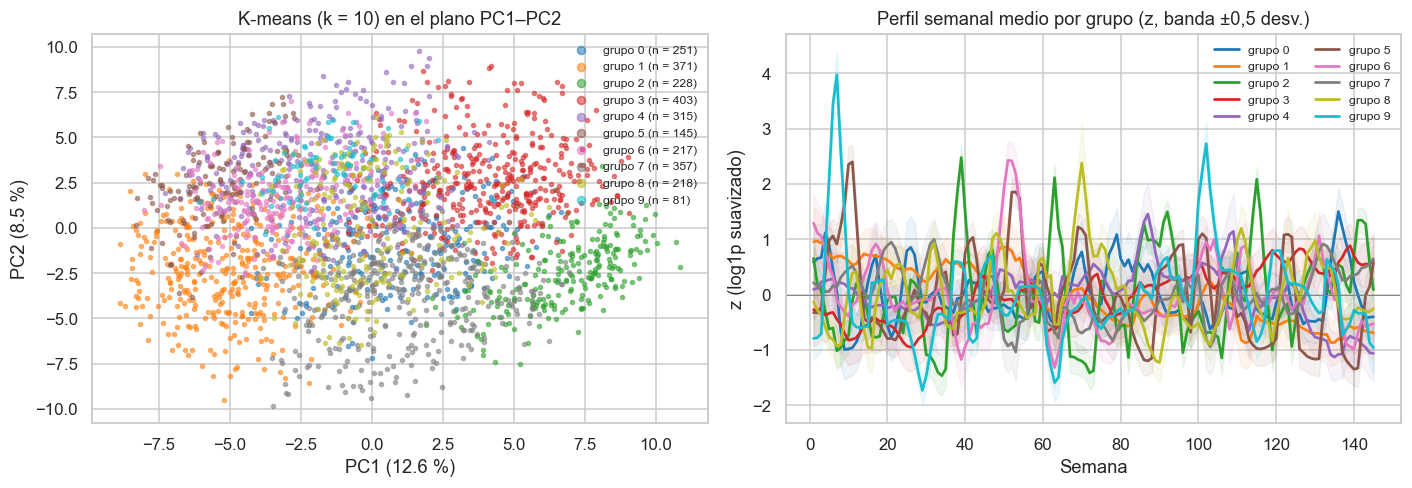

In [53]:
colors = sns.color_palette("tab10", K_KM)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
for g in range(K_KM):
    m = (lab == g).to_numpy()
    ax[0].scatter(T[m, 0], T[m, 1], s=7, alpha=0.55, color=colors[g], label=f"grupo {g} (n = {m.sum()})")
ax[0].set(title=f"K-means (k = {K_KM}) en el plano PC1–PC2", xlabel=f"PC1 ({evr[0]*100:.1f} %)", ylabel=f"PC2 ({evr[1]*100:.1f} %)")
ax[0].legend(frameon=False, fontsize=8, markerscale=2)

for g in range(K_KM):
    m = (lab == g).to_numpy()
    mu, sd = Zv[m].mean(axis=0), Zv[m].std(axis=0)
    ax[1].plot(weeks, mu, color=colors[g], lw=1.8, label=f"grupo {g}")
    ax[1].fill_between(weeks, mu - 0.5 * sd, mu + 0.5 * sd, color=colors[g], alpha=0.08)
ax[1].axhline(0, color="grey", lw=0.6)
ax[1].set(title="Perfil semanal medio por grupo (z, banda ±0,5 desv.)", xlabel="Semana", ylabel="z (log1p suavizado)")
ax[1].legend(frameon=False, fontsize=8, ncol=2)
plt.tight_layout()
savefig("05_kmeans_perfiles")

- En el plano PC1-PC2 los grupos se solapan mucho, lo que coincide con la silueta baja.
- Varios grupos se definen por picos en semanas concretas: el grupo 9 tiene picos hacia las semanas 7 y 102, y los grupos 5, 2 y 8 también tienen picos marcados.
- Otros grupos (1, 3, 4, 7) son más planos o con tendencia suave: el grupo 1 empieza alto y baja de forma gradual.

## Estabilidad de la particion 

ARI entre semillas (n_init=1, 10 semillas): media 0.635 | mínimo 0.423

ARI mitad 1 vs mitad 2     : 0.200
ARI mitad 1 vs periodo completo: 0.310 | mitad 2 vs periodo completo: 0.330


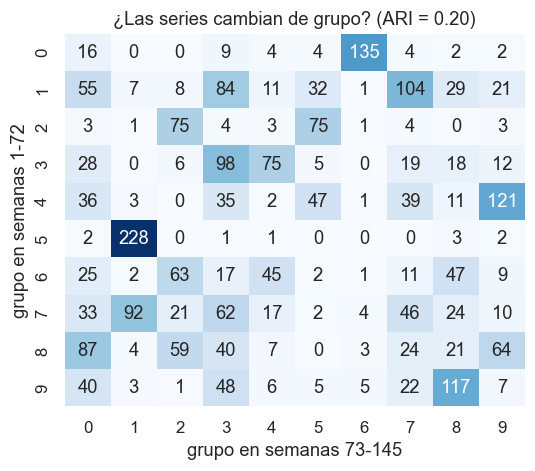

In [54]:
# --- (1) Sensibilidad a la inicialización ---
labs_seed = [KMeans(K_KM, n_init=1, random_state=s).fit_predict(T) for s in range(10)]
ari_seed = [adjusted_rand_score(labs_seed[i], labs_seed[j]) for i in range(10) for j in range(i + 1, 10)]
print(f"ARI entre semillas (n_init=1, 10 semillas): media {np.mean(ari_seed):.3f} | mínimo {np.min(ari_seed):.3f}")

# --- (2) Mitades temporales ---
def fit_pca_kmeans(Zm, n_pc=N_PC, k=K_KM, seed=SEED):
    Zm = np.asarray(Zm)
    Tm = PCA(n_components=n_pc, svd_solver="full", random_state=seed).fit_transform(Zm)
    return KMeans(k, n_init=N_INIT, random_state=seed).fit_predict(Tm)

lab_h1 = fit_pca_kmeans(Z_h1)
lab_h2 = fit_pca_kmeans(Z_h2)
ari_h1h2 = adjusted_rand_score(lab_h1, lab_h2)
ari_h1f  = adjusted_rand_score(lab_h1, lab)
ari_h2f  = adjusted_rand_score(lab_h2, lab)
print(f"\nARI mitad 1 vs mitad 2     : {ari_h1h2:.3f}")
print(f"ARI mitad 1 vs periodo completo: {ari_h1f:.3f} | mitad 2 vs periodo completo: {ari_h2f:.3f}")

stab = pd.DataFrame({"comparación": ["semillas (media)", "semillas (mínimo)", "mitad 1 vs mitad 2", "mitad 1 vs completo", "mitad 2 vs completo"],
                     "ARI": [np.mean(ari_seed), np.min(ari_seed), ari_h1h2, ari_h1f, ari_h2f]}).round(3)
save_table(stab, "05_kmeans_estabilidad", index=False)

fig, ax = plt.subplots(figsize=(5.4, 4.4))
sns.heatmap(pd.crosstab(pd.Series(lab_h1, name="grupo en semanas 1-72"), pd.Series(lab_h2, name="grupo en semanas 73-145")),
            annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
ax.set_title(f"¿Las series cambian de grupo? (ARI = {ari_h1h2:.2f})")
savefig("05_kmeans_estabilidad_mitades")


- Entre semillas (`n_init=1`) el ARI medio es 0,635 y el mínimo 0,423: la partición depende de la inicialización, aunque no por completo.
- Entre mitades temporales el ARI es **0,200**, muy por debajo del nivel de ruido de las semillas. Los perfiles **no son estables en el tiempo** con k = 10.
- La tabla de contingencia muestra excepciones: 228 series del grupo 5 de la primera mitad pasan al grupo 1 de la segunda, y los grupos 0 y 9 también se concentran en un solo destino. Los demás se reparten entre varios grupos.
- Una explicación posible es que los grupos se definen por picos en semanas específicas, que no coinciden entre mitades. Es una hipótesis, no un resultado.

## Relacion de los grupos con precio, promocion y metadatos

,series,log_volumen,descuento,emailer,homepage
cluster,,,,,
0,251,4.643,0.103,0.069,0.111
1,371,5.017,0.056,0.046,0.110
2,228,5.016,0.091,0.283,0.228
3,403,4.430,0.049,0.037,0.097
4,315,5.046,0.036,0.040,0.140
5,145,4.237,0.075,0.173,0.151
6,217,4.987,0.048,0.071,0.124
7,357,5.113,0.056,0.057,0.066
8,218,5.830,0.051,0.126,0.119


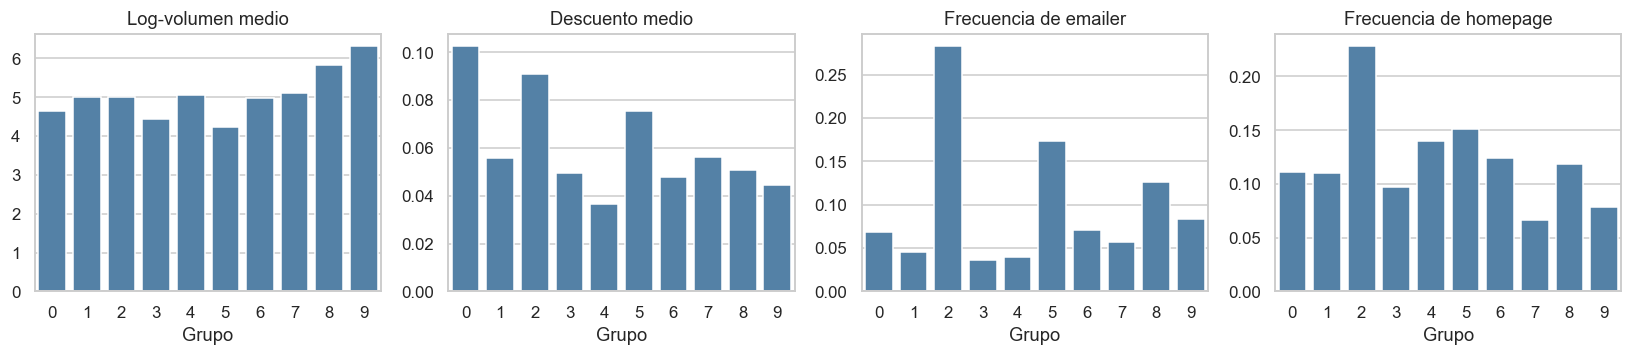

In [55]:
ia = info.join(lab)

perfil = (ia.groupby("cluster")
            .agg(series=("log_volumen", "size"),
                 log_volumen=("log_volumen", "mean"),
                 descuento=("descuento", "mean"),
                 emailer=("emailer_for_promotion", "mean"),
                 homepage=("homepage_featured", "mean"))
            .round(3))
save_table(perfil, "05_kmeans_perfil_grupos")
display(perfil)

fig, ax = plt.subplots(1, 4, figsize=(15, 3.4))
for a, col, t in zip(ax, ["log_volumen", "descuento", "emailer_for_promotion", "homepage_featured"],
                     ["Log-volumen medio", "Descuento medio", "Frecuencia de emailer", "Frecuencia de homepage"]):
    sns.barplot(data=ia.reset_index(), x="cluster", y=col, errorbar=None, color="steelblue", ax=a)
    a.set(title=t, xlabel="Grupo", ylabel="")
plt.tight_layout()
savefig("05_kmeans_promocion_precio")

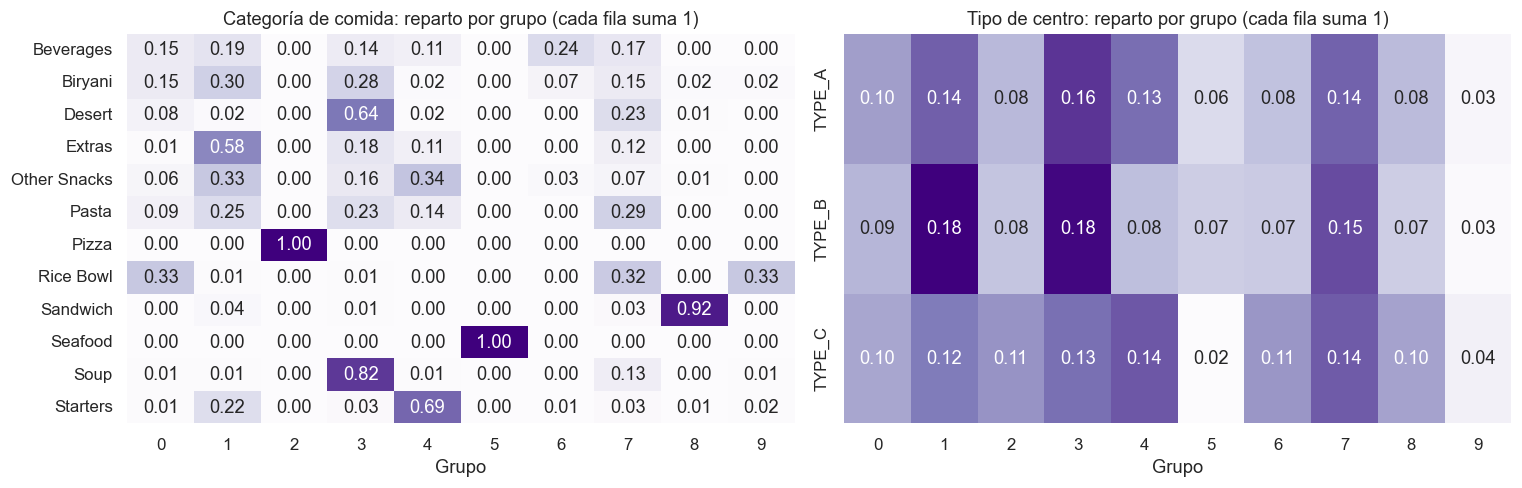

In [ ]:
#¿qué fracción cae en cada grupo?
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
for a, col, t in zip(ax, ["category", "center_type"], ["Categoría de comida", "Tipo de centro"]):
    tab = pd.crosstab(ia[col], ia["cluster"], normalize="index")
    sns.heatmap(tab, annot=True, fmt=".2f", cmap="Purples", cbar=False, ax=a)
    a.set(title=f"{t}: reparto por grupo (cada fila suma 1)", xlabel="Grupo", ylabel="")
plt.tight_layout()
savefig("05_kmeans_composicion")

- Aunque `Z` no incluye el volumen, los grupos difieren en él: el log-volumen va de 4,24 (grupo 5) a 6,32 (grupo 9).
- El grupo 2 tiene la mayor frecuencia de promoción (emailer 28 %, homepage 23 %); el grupo 5 le sigue (17 % y 15 %). Los demás tienen emailer de 13 % o menos.
- El descuento medio es bajo en todos los grupos (3,6 % a 10,3 %).
- Es una **asociación, no causalidad**: los grupos con picos coinciden con más promoción, pero las promociones no se asignan al azar.